In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from kpi import config as C

pd.set_option("display.width", 200)
print("ROOT:", C.ROOT)
print("series folder exists:", C.SERIES_DIR.exists())

ROOT: D:\Projects\Projects\Nextranet-kpi-project\Nextranet-kpi-project
series folder exists: True


In [2]:
def list_series():
    return sorted(p.stem for p in C.SERIES_DIR.glob("*.csv"))

names = list_series()
print(len(names), "files")
for n in names:
    print(" ", n)

17 files
  ec2_cpu_utilization_24ae8d
  ec2_cpu_utilization_53ea38
  ec2_cpu_utilization_5f5533
  ec2_cpu_utilization_77c1ca
  ec2_cpu_utilization_825cc2
  ec2_cpu_utilization_ac20cd
  ec2_cpu_utilization_c6585a
  ec2_cpu_utilization_fe7f93
  ec2_disk_write_bytes_1ef3de
  ec2_disk_write_bytes_c0d644
  ec2_network_in_257a54
  ec2_network_in_5abac7
  elb_request_count_8c0756
  grok_asg_anomaly
  iio_us-east-1_i-a2eb1cd9_NetworkIn
  rds_cpu_utilization_cc0c53
  rds_cpu_utilization_e47b3b


In [3]:
raw = pd.read_csv(C.SERIES_DIR / "ec2_cpu_utilization_24ae8d.csv", parse_dates=["timestamp"])
display(raw.head())
display(raw.tail())
print("shape:", raw.shape)
print(raw.dtypes)

,timestamp,value
0,2014-02-14 14:30:00,0.132
1,2014-02-14 14:35:00,0.134
2,2014-02-14 14:40:00,0.134
3,2014-02-14 14:45:00,0.134
4,2014-02-14 14:50:00,0.134


,timestamp,value
4027,2014-02-28 14:05:00,0.132
4028,2014-02-28 14:10:00,0.134
4029,2014-02-28 14:15:00,0.134
4030,2014-02-28 14:20:00,0.134
4031,2014-02-28 14:25:00,0.134


shape: (4032, 2)
timestamp    datetime64[ns]
value               float64
dtype: object


In [4]:
dst = pd.read_csv(C.SERIES_DIR / "ec2_disk_write_bytes_1ef3de.csv", parse_dates=["timestamp"])
print("rows:", len(dst), "| duplicated timestamps:", dst["timestamp"].duplicated().sum())
i = dst.index[dst["timestamp"].duplicated(keep=False)][0]
display(dst.iloc[i-3:i+16])

rows: 4730 | duplicated timestamps: 11


,timestamp,value
2115,2014-03-09 01:49:00,0.0
2116,2014-03-09 01:54:00,0.0
2117,2014-03-09 01:59:00,0.0
2118,2014-03-09 03:00:00,0.0
2119,2014-03-09 03:00:00,0.0
2120,2014-03-09 03:00:00,0.0
2121,2014-03-09 03:00:00,0.0
2122,2014-03-09 03:00:00,0.0
2123,2014-03-09 03:00:00,0.0
2124,2014-03-09 03:00:00,0.0


In [5]:
df = dst.copy()
ts = df["timestamp"]

phase = (ts.dt.minute % 5).mode().iloc[0]
print("normal phase (minute % 5):", phase)

bad = ts.duplicated(keep=False) | ((ts.dt.minute % 5) != phase)
print("bad rows:", int(bad.sum()))

idx = np.flatnonzero(bad.to_numpy())
print("their row numbers:", idx)
print("one contiguous block:", bool((np.diff(idx) == 1).all()))

normal phase (minute % 5): 4
bad rows: 12
their row numbers: [2118 2119 2120 2121 2122 2123 2124 2125 2126 2127 2128 2129]
one contiguous block: True


In [6]:
new = pd.date_range(ts.iloc[idx[0] - 1] + pd.Timedelta(minutes=5),
                    periods=idx.size, freq=C.STEP)
print("the 12 correct timestamps:")
print(new)
print("last new one:", new[-1], "| next real row:", ts.iloc[idx[-1] + 1],
      "| no overlap:", bool(new[-1] < ts.iloc[idx[-1] + 1]))

the 12 correct timestamps:
DatetimeIndex(['2014-03-09 02:04:00', '2014-03-09 02:09:00', '2014-03-09 02:14:00', '2014-03-09 02:19:00', '2014-03-09 02:24:00', '2014-03-09 02:29:00', '2014-03-09 02:34:00', '2014-03-09 02:39:00',
               '2014-03-09 02:44:00', '2014-03-09 02:49:00', '2014-03-09 02:54:00', '2014-03-09 02:59:00'],
              dtype='datetime64[ns]', freq='5min')
last new one: 2014-03-09 02:59:00 | next real row: 2014-03-09 03:04:00 | no overlap: True


In [7]:
df.loc[idx, "timestamp"] = new.to_numpy()
display(df.iloc[idx[0] - 2 : idx[-1] + 3])   # same rows as before, now correctly stamped

,timestamp,value
2116,2014-03-09 01:54:00,0.0
2117,2014-03-09 01:59:00,0.0
2118,2014-03-09 02:04:00,0.0
2119,2014-03-09 02:09:00,0.0
2120,2014-03-09 02:14:00,0.0
2121,2014-03-09 02:19:00,0.0
2122,2014-03-09 02:24:00,0.0
2123,2014-03-09 02:29:00,0.0
2124,2014-03-09 02:34:00,0.0
2125,2014-03-09 02:39:00,0.0


In [8]:
def _restamp_block(df):
    ts = df["timestamp"]
    phase = (ts.dt.minute % 5).mode().iloc[0]
    bad = ts.duplicated(keep=False) | ((ts.dt.minute % 5) != phase)
    idx = np.flatnonzero(bad.to_numpy())
    if idx.size == 0:
        return df, 0
    assert (np.diff(idx) == 1).all(), "bad rows are not one contiguous block"
    assert 0 < idx[0] and idx[-1] < len(df) - 1
    new = pd.date_range(ts.iloc[idx[0] - 1] + pd.Timedelta(minutes=5),
                        periods=idx.size, freq=C.STEP)
    assert new[-1] < ts.iloc[idx[-1] + 1], "re-stamped block would overlap next row"
    df = df.copy()
    df.loc[idx, "timestamp"] = new.to_numpy()
    return df, int(idx.size)

for n in ["ec2_disk_write_bytes_1ef3de", "ec2_network_in_5abac7", "ec2_cpu_utilization_24ae8d"]:
    d = pd.read_csv(C.SERIES_DIR / f"{n}.csv", parse_dates=["timestamp"])
    fixed, k = _restamp_block(d)
    print(f"{n:35s} rows fixed: {k:2d} | duplicates left: {fixed['timestamp'].duplicated().sum()}")

ec2_disk_write_bytes_1ef3de         rows fixed: 12 | duplicates left: 0
ec2_network_in_5abac7               rows fixed: 12 | duplicates left: 0
ec2_cpu_utilization_24ae8d          rows fixed:  0 | duplicates left: 0


In [9]:
name = "ec2_cpu_utilization_ac20cd"
df = pd.read_csv(C.SERIES_DIR / f"{name}.csv", parse_dates=["timestamp"])
df, n_fixed = _restamp_block(df)

s = df.set_index("timestamp")["value"].astype(float)
grid = pd.date_range(s.index[0], s.index[-1], freq=C.STEP)

print("rows in file:", len(s))
print("slots the grid should have:", len(grid))
print("missing slots:", len(grid) - len(s))
print("every real timestamp is on the grid:", bool(s.index.isin(grid).all()))

rows in file: 4032
slots the grid should have: 4037
missing slots: 5
every real timestamp is on the grid: True


In [10]:
s_grid = s.reindex(grid)          # put the data on the full grid; absent slots become NaN
imputed = s_grid.isna()           # remember which slots were empty BEFORE filling
print("empty slots:", int(imputed.sum()))
display(s_grid[imputed])

empty slots: 5


2014-04-07 13:39:00   NaN
2014-04-07 13:44:00   NaN
2014-04-14 23:49:00   NaN
2014-04-14 23:54:00   NaN
2014-04-14 23:59:00   NaN
Name: value, dtype: float64

In [11]:
s_filled = s_grid.interpolate(method="time", limit=6, limit_direction="both")
print("still empty after filling:", int(s_filled.isna().sum()))

j = np.flatnonzero(imputed.to_numpy())[0]          # first gap
display(pd.DataFrame({"before": s_grid, "after": s_filled, "imputed": imputed}).iloc[j-3:j+6])

still empty after filling: 0


,before,after,imputed
2014-04-07 13:24:00,34.456,34.456000,False
2014-04-07 13:29:00,38.208,38.208000,False
2014-04-07 13:34:00,35.610,35.610000,False
2014-04-07 13:39:00,NaN,33.148333,True
2014-04-07 13:44:00,NaN,30.686667,True
2014-04-07 13:49:00,28.225,28.225000,False
2014-04-07 13:54:00,35.788,35.788000,False
2014-04-07 13:59:00,33.498,33.498000,False
2014-04-07 14:04:00,34.320,34.320000,False


In [12]:
def load_series(name, max_fill=6):
    df = pd.read_csv(C.SERIES_DIR / f"{name}.csv", parse_dates=["timestamp"])
    df, n_fixed = _restamp_block(df)
    assert df["timestamp"].is_monotonic_increasing
    assert not df["timestamp"].duplicated().any()

    s = df.set_index("timestamp")["value"].astype(float)
    grid = pd.date_range(s.index[0], s.index[-1], freq=C.STEP)
    assert s.index.isin(grid).all(), "timestamps off the 5-min grid"
    s = s.reindex(grid)
    imputed = s.isna()
    s = s.interpolate(method="time", limit=max_fill, limit_direction="both")
    assert s.notna().all()

    out = pd.DataFrame({"value": s, "imputed": imputed})
    out.attrs.update(name=name, restamped_rows=n_fixed)
    return out

for n in ["ec2_cpu_utilization_ac20cd", "ec2_disk_write_bytes_1ef3de"]:
    d = load_series(n)
    print(n, "| shape:", d.shape, "| imputed:", int(d["imputed"].sum()), "| restamped:", d.attrs["restamped_rows"])
display(d.head())

ec2_cpu_utilization_ac20cd | shape: (4037, 2) | imputed: 5 | restamped: 0
ec2_disk_write_bytes_1ef3de | shape: (4730, 2) | imputed: 0 | restamped: 12


,value,imputed
2014-03-01 17:34:00,0.0,False
2014-03-01 17:39:00,0.0,False
2014-03-01 17:44:00,0.0,False
2014-03-01 17:49:00,0.0,False
2014-03-01 17:54:00,0.0,False


In [14]:
df = load_series("ec2_cpu_utilization_24ae8d")
cut = int(len(df) * 0.7)
print("rows:", len(df), "| 70% =", len(df) * 0.7, "| cut (int) =", cut)
train, test = df.iloc[:cut], df.iloc[cut:]
print("train:", train.index[0], "->", train.index[-1], f"({len(train)} rows)")
print("test: ", test.index[0], "->", test.index[-1], f"({len(test)} rows)")

rows: 4032 | 70% = 2822.3999999999996 | cut (int) = 2822
train: 2014-02-14 14:30:00 -> 2014-02-24 09:35:00 (2822 rows)
test:  2014-02-24 09:40:00 -> 2014-02-28 14:25:00 (1210 rows)


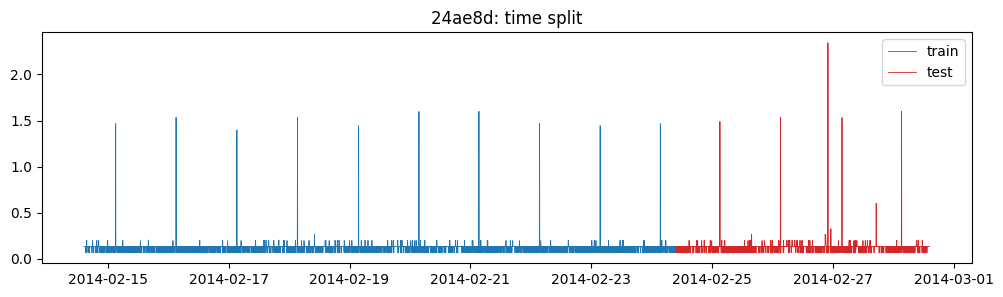

In [15]:
def split(df, frac=C.TRAIN_FRAC):
    cut = int(len(df) * frac)
    return df.iloc[:cut], df.iloc[cut:]

train, test = split(df)
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(train.index, train["value"], lw=.6, label="train")
ax.plot(test.index, test["value"], lw=.6, color="tab:red", label="test")
ax.legend(); ax.set_title("24ae8d: time split")
plt.show()

In [16]:
with open(C.LABELS, encoding="utf-8") as f1, open(C.WINDOWS, encoding="utf-8") as f2:
    labels, windows = json.load(f1), json.load(f2)

key = "realAWSCloudwatch/ec2_cpu_utilization_24ae8d.csv"
print("labels :", labels[key])
print("windows:", windows[key])

labels : ['2014-02-26 22:05:00', '2014-02-27 17:15:00']
windows: [['2014-02-26 13:45:00.000000', '2014-02-27 06:25:00.000000'], ['2014-02-27 08:55:00.000000', '2014-02-28 01:35:00.000000']]


In [17]:
key = "realAWSCloudwatch/iio_us-east-1_i-a2eb1cd9_NetworkIn.csv"
L = [pd.Timestamp(x) for x in labels[key]]
W = [(pd.Timestamp(a), pd.Timestamp(b)) for a, b in windows[key]]
print("labels:", L)
print("windows:", W)

for t in L:
    inside = [i for i, (a, b) in enumerate(W) if a <= t <= b]
    dist = [abs((a - t).total_seconds()) for a, _ in W]
    print(f"\nlabel {t}")
    print("  windows that contain it:", inside)
    print("  distance to each window start (s):", dist)
    print("  -> chosen window:", inside[0] if inside else int(np.argmin(dist)))

labels: [Timestamp('2013-10-10 09:35:00'), Timestamp('2013-10-10 20:40:00')]
windows: [(Timestamp('2013-10-10 10:35:00'), Timestamp('2013-10-10 15:45:00')), (Timestamp('2013-10-10 18:05:00'), Timestamp('2013-10-10 23:15:00'))]

label 2013-10-10 09:35:00
  windows that contain it: []
  distance to each window start (s): [3600.0, 30600.0]
  -> chosen window: 0

label 2013-10-10 20:40:00
  windows that contain it: [1]
  distance to each window start (s): [36300.0, 9300.0]
  -> chosen window: 1


In [18]:
from functools import lru_cache

@lru_cache(maxsize=1)
def _raw_labels():
    with open(C.LABELS, encoding="utf-8") as f1, open(C.WINDOWS, encoding="utf-8") as f2:
        return json.load(f1), json.load(f2)

def load_events(name):
    labels, windows = _raw_labels()
    key = f"realAWSCloudwatch/{name}.csv"
    L = [pd.Timestamp(x) for x in labels[key]]
    W = [(pd.Timestamp(a), pd.Timestamp(b)) for a, b in windows[key]]
    rows = []
    for t in L:
        inside = [i for i, (a, b) in enumerate(W) if a <= t <= b]
        w = inside[0] if inside else int(np.argmin([abs((a - t).total_seconds()) for a, _ in W]))
        rows.append(dict(label_time=t, window_id=w,
                         window_start=W[w][0], window_end=W[w][1]))
    return pd.DataFrame(rows, columns=["label_time", "window_id", "window_start", "window_end"])

for n in ["ec2_cpu_utilization_fe7f93", "iio_us-east-1_i-a2eb1cd9_NetworkIn", "ec2_cpu_utilization_c6585a"]:
    print("\n", n)
    display(load_events(n))


 ec2_cpu_utilization_fe7f93


,label_time,window_id,window_start,window_end
0,2014-02-17 06:12:00,0,2014-02-17 00:37:00,2014-02-17 11:47:00
1,2014-02-22 00:02:00,1,2014-02-21 18:27:00,2014-02-22 05:37:00
2,2014-02-23 15:17:00,2,2014-02-23 09:42:00,2014-02-23 20:52:00



 iio_us-east-1_i-a2eb1cd9_NetworkIn


,label_time,window_id,window_start,window_end
0,2013-10-10 09:35:00,0,2013-10-10 10:35:00,2013-10-10 15:45:00
1,2013-10-10 20:40:00,1,2013-10-10 18:05:00,2013-10-10 23:15:00



 ec2_cpu_utilization_c6585a


,label_time,window_id,window_start,window_end


In [19]:
rows = []
for n in list_series():
    d = load_series(n)
    tr, te = split(d)
    ev = load_events(n)
    k = int((ev["label_time"] >= te.index[0]).sum())      # labels falling in the test part
    rows.append(dict(file=n, rows=len(d), restamped=d.attrs["restamped_rows"],
                     imputed=int(d["imputed"].sum()), train=len(tr), test=len(te),
                     labels_train=len(ev) - k, labels_test=k, windows=ev["window_id"].nunique()))
summary = pd.DataFrame(rows)
display(summary)
print(summary[["restamped", "imputed", "labels_train", "labels_test", "windows"]].sum())

,file,rows,restamped,imputed,train,test,labels_train,labels_test,windows
0,ec2_cpu_utilization_24ae8d,4032,0,0,2822,1210,0,2,2
1,ec2_cpu_utilization_53ea38,4032,0,0,2822,1210,2,0,2
2,ec2_cpu_utilization_5f5533,4032,0,0,2822,1210,1,1,2
3,ec2_cpu_utilization_77c1ca,4032,0,0,2822,1210,1,0,1
4,ec2_cpu_utilization_825cc2,4034,0,2,2823,1211,2,0,1
5,ec2_cpu_utilization_ac20cd,4037,0,5,2825,1212,0,1,1
6,ec2_cpu_utilization_c6585a,4032,0,0,2822,1210,0,0,0
7,ec2_cpu_utilization_fe7f93,4032,0,0,2822,1210,3,0,3
8,ec2_disk_write_bytes_1ef3de,4730,12,0,3311,1419,1,0,1
9,ec2_disk_write_bytes_c0d644,4032,0,0,2822,1210,2,1,3


restamped       24
imputed         18
labels_train    22
labels_test      9
windows         30
dtype: int64


In [20]:
assert summary["labels_train"].sum() == 22
assert summary["labels_test"].sum() == 9
assert (summary["labels_test"] > 0).sum() == 7
assert summary["windows"].sum() == 30
print("OK: 22 train labels, 9 test labels in 7 files, 30 windows (matches the assignment)")

OK: 22 train labels, 9 test labels in 7 files, 30 windows (matches the assignment)


In [21]:
try:
    from kpi import data as kd
    for n in list_series():
        pd.testing.assert_frame_equal(load_series(n), kd.load_series(n))
    print("data.py matches the notebook functions for all 17 files")
except ImportError:
    print("kpi/data.py not found yet: create it first, then re-run this cell")

data.py matches the notebook functions for all 17 files
